# Stage 3: CyTOF annotation

This stage reloads the Stage 2 pooled scaled GFP-high table, runs the source notebook's cell-identity UMAP and Leiden diagnostic, assigns manual UMAP regions, fills remaining labels with the source XGBoost configuration, and exports the labeled scaled table.

In [1]:
# ruff: noqa: E402, E501
from pathlib import Path
import sys

# Support launching Jupyter from either the checkout root or its notebooks folder.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "app").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
# Prefer this checkout over another installed copy or worktree of app.
sys.path.insert(0, str(PROJECT_ROOT))
import app  # noqa: E402

print(f"Kernel executable: {sys.executable}")
print(f"Working directory: {Path.cwd().resolve()}")
print(f"Imported app package: {Path(app.__file__).resolve()}")

# Fail early if Python resolved app from outside this checkout.
if Path(app.__file__).resolve().parent != PROJECT_ROOT / "app":
    raise RuntimeError("app was imported from outside the intended checkout")

Kernel executable: /Users/yishai/Desktop/epigenetics_field_theory/.venv/bin/python
Working directory: /Users/yishai/Desktop/epigenetics_field_theory/notebooks
Imported app package: /Users/yishai/Desktop/epigenetics_field_theory/app/__init__.py


In [2]:
from app.dotenv import OUTPUT_ROOT,ANNOTATION_FILE
from app.preprocessing import add_cell_uid
import pandas as pd
from IPython.display import display
from app.annotation import (
    assign_manual_labels,
    calculate_umap,
    calc_leiden,
    get_umap_markers,
    load_umap,
    plot_cluster_heatmap,
    plot_clusters,
    plot_clusters_by_condition,
    plot_umap_staining,
    predict_noise_xgboost,
    save_labeled_data,
)

In [3]:
EXPERIMENTS = ["batch2", "batch3", "batch4_extra_treatment"]
ZSCORED_DIR = (
    OUTPUT_ROOT
    / "5. GFP_high_balanced_per_experiment, & Z_scored"
    / "7. GFP_high_balanced_per_experiment_ZSCORED"
)
UMAP_ROOT = (
    OUTPUT_ROOT / "6. plots - GFP+ analyses" / "GFP_high_balanced_ZSCORED_UMAP_by_marker_group"
)
MARKER_GROUP = "cell_identity"
CELL_IDENTITY_MARKERS = [
    "CD109",
    "CD133",
    "CD24",
    "CD44",
    "CXCR4",
    "E-cadherin",
    "EpCAM",
    "GAL4",
    "GATA6",
    "KI67",
    "KRT17",
    "KRT5",
    "MHC-II",
    "S100A4",
    "SLC44A4",
    "TSPAN8",
    "Vimentin",
    "pRb",
]
PRESENT_MARKERS = [
    "GAL4",
    "TSPAN8",
    "GATA6",
    "CD109",
    "CD24",
    "CD44",
    "CD45",
    "CXCR4",
    "DNA",
    "E-cadherin",
    "EZH2",
    "EpCAM",
    "GFP",
    "H2AK119ub",
    "H3",
    "H3.3",
    "H3K27ac",
    "H3K27me2",
    "H3K27me3",
    "H3K36me2",
    "H3K36me3",
    "H3K4me1",
    "H3K4me2",
    "H3K4me3",
    "H3K9ac",
    "H3K9me2",
    "H3K9me3",
    "H4",
    "H4K16ac",
    "H4K20me3",
    "KI67",
    "KRT17",
    "KRT5",
    "MBD",
    "MHC-II",
    "Pan-KRT",
    "S100A4",
    "Vimentin",
    "pH2A.X",
    "pRb",
]

staining = False

## Load Data

In [4]:
if not (ZSCORED_DIR / "all_GFP_high_BALANCED_ZSCORED.csv").is_file():
    raise FileNotFoundError(ZSCORED_DIR / "all_GFP_high_BALANCED_ZSCORED.csv")
pooled_scaled = pd.read_csv(ZSCORED_DIR / "all_GFP_high_BALANCED_ZSCORED.csv", low_memory=False)
pooled_scaled = add_cell_uid(pooled_scaled)

## 1. Dimensionality reduction

Fit the active source UMAP on pooled scaled cell-identity markers and save pooled and per-sample coordinates, plots, and a summary.

Missing cell-identity markers: ['CD133', 'CXCR4', 'MHC-II', 'S100A4', 'SLC44A4']


/Users/yishai/Desktop/epigenetics_field_theory/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


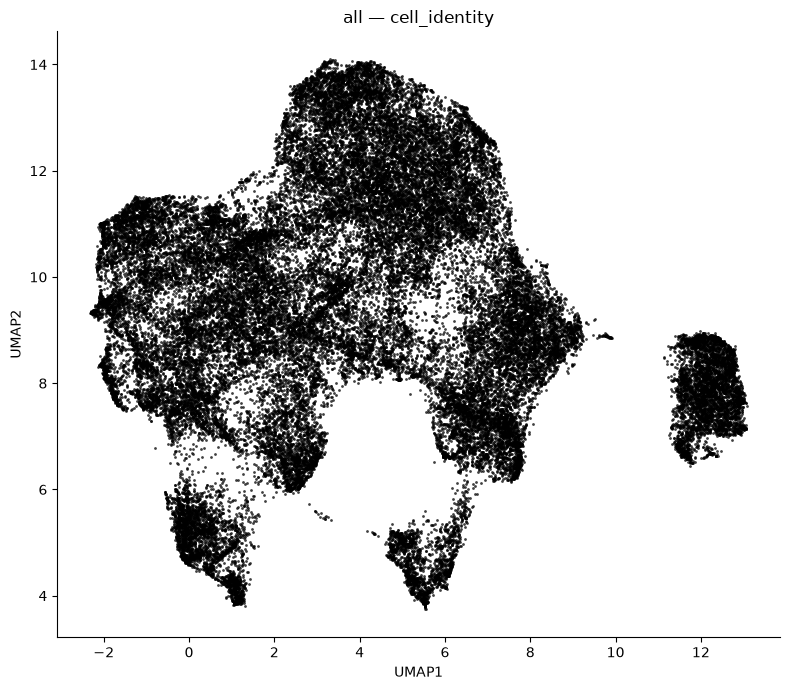

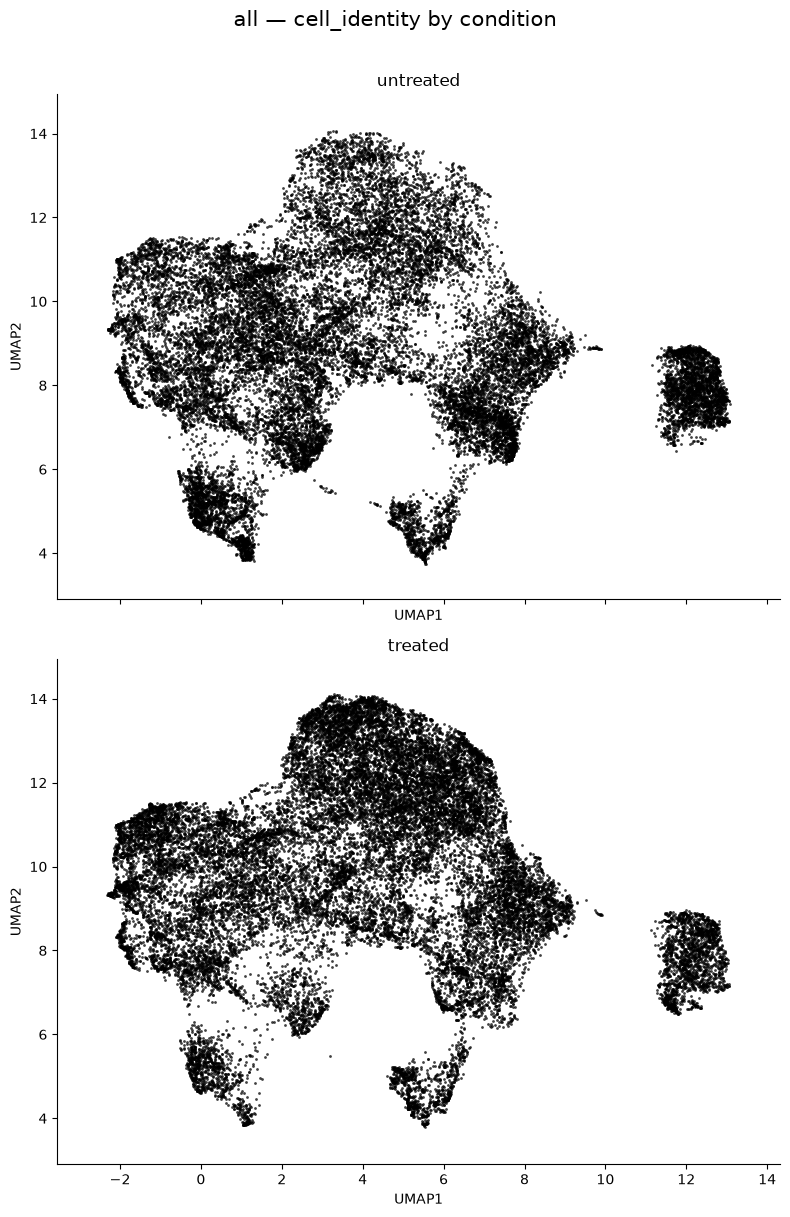

,marker_group,experiment,n_cells,n_markers_used,markers_used,full_umap_plot,condition_umap_plot,all_coordinates_file,per_sample_coordinates_dir
0,cell_identity,all,57246,13,"CD109, CD24, CD44, E-cadherin, EpCAM, GAL4, GA...",/Users/yishai/Desktop/epigenetics_field_theory...,/Users/yishai/Desktop/epigenetics_field_theory...,/Users/yishai/Desktop/epigenetics_field_theory...,/Users/yishai/Desktop/epigenetics_field_theory...


In [5]:

marker_cols, missing_markers = get_umap_markers(pooled_scaled, CELL_IDENTITY_MARKERS)
print("Missing cell-identity markers:", missing_markers)
coordinates, umap_summary = calculate_umap(
    pooled_scaled.copy(),
    marker_cols,
    MARKER_GROUP,
    "all",
    {
        "batch2": ["untreated", "treated"],
        "batch3": ["untreated", "treated"],
        "batch4_extra_treatment": ["untreated", "treated"],
    },
    OUTPUT_ROOT,
    n_neighbors=15,
    min_dist=0.001,
    random_state=42,
)
umap_summary_frame = pd.DataFrame([umap_summary])
umap_summary_frame.to_csv(UMAP_ROOT / "UMAP_summary_cell_identity_and_epigenetic.csv", index=False)
display(umap_summary_frame)

## 2. Leiden clustering diagnostics

Reload saved coordinates and use the source symmetric kNN graph, RBConfiguration partition, 100 neighbors, resolution 0.07, seed 42, and two Leiden iterations.

Leiden computation: 32.82 seconds
Leiden clusters: 7


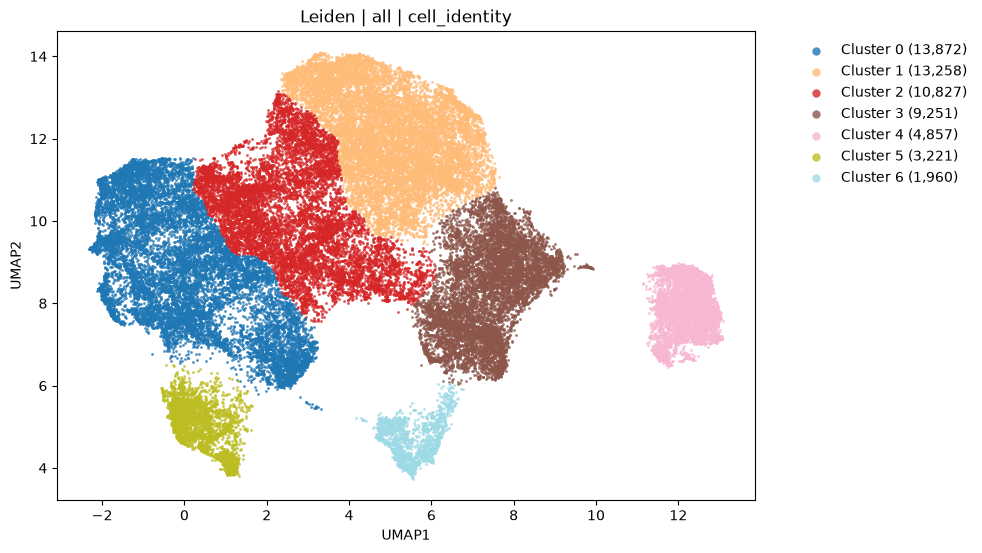

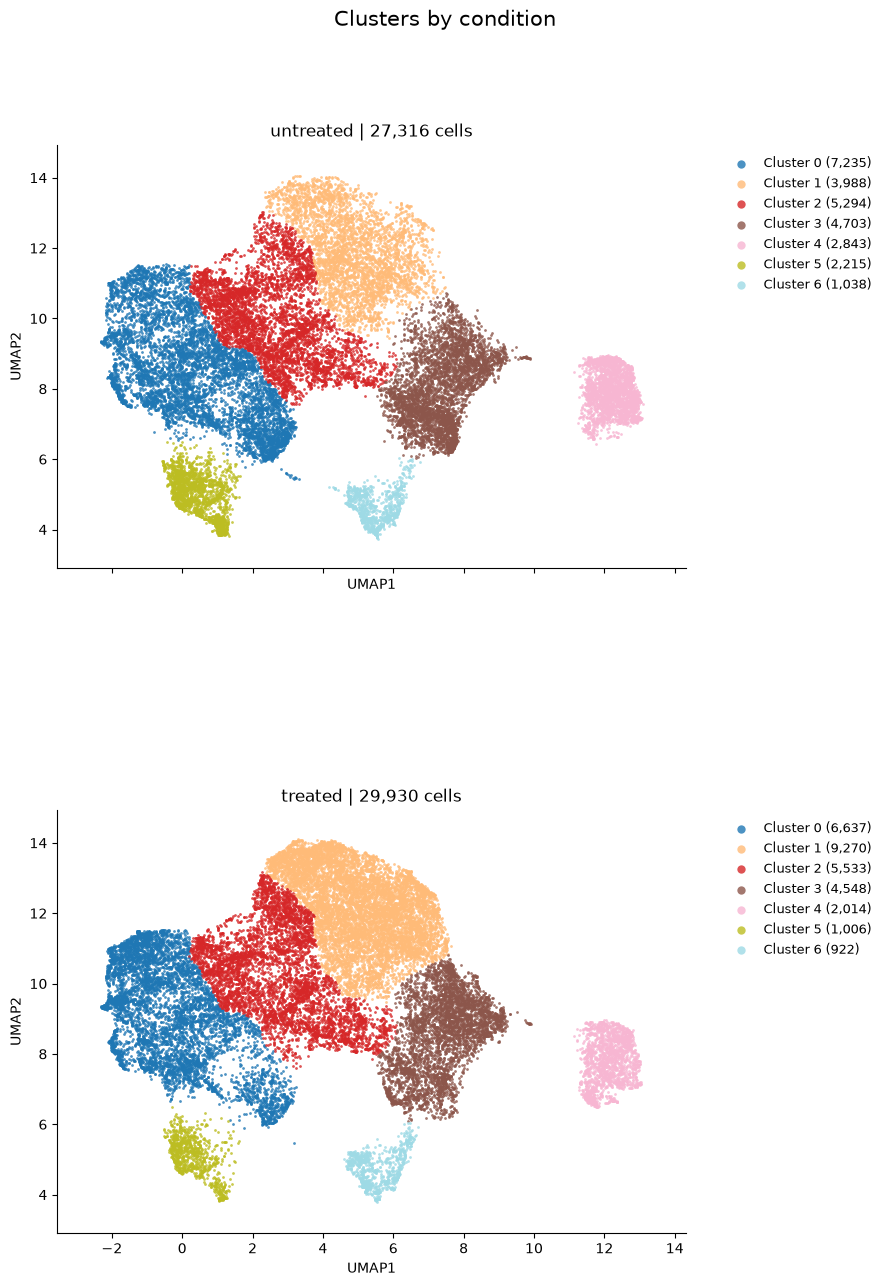

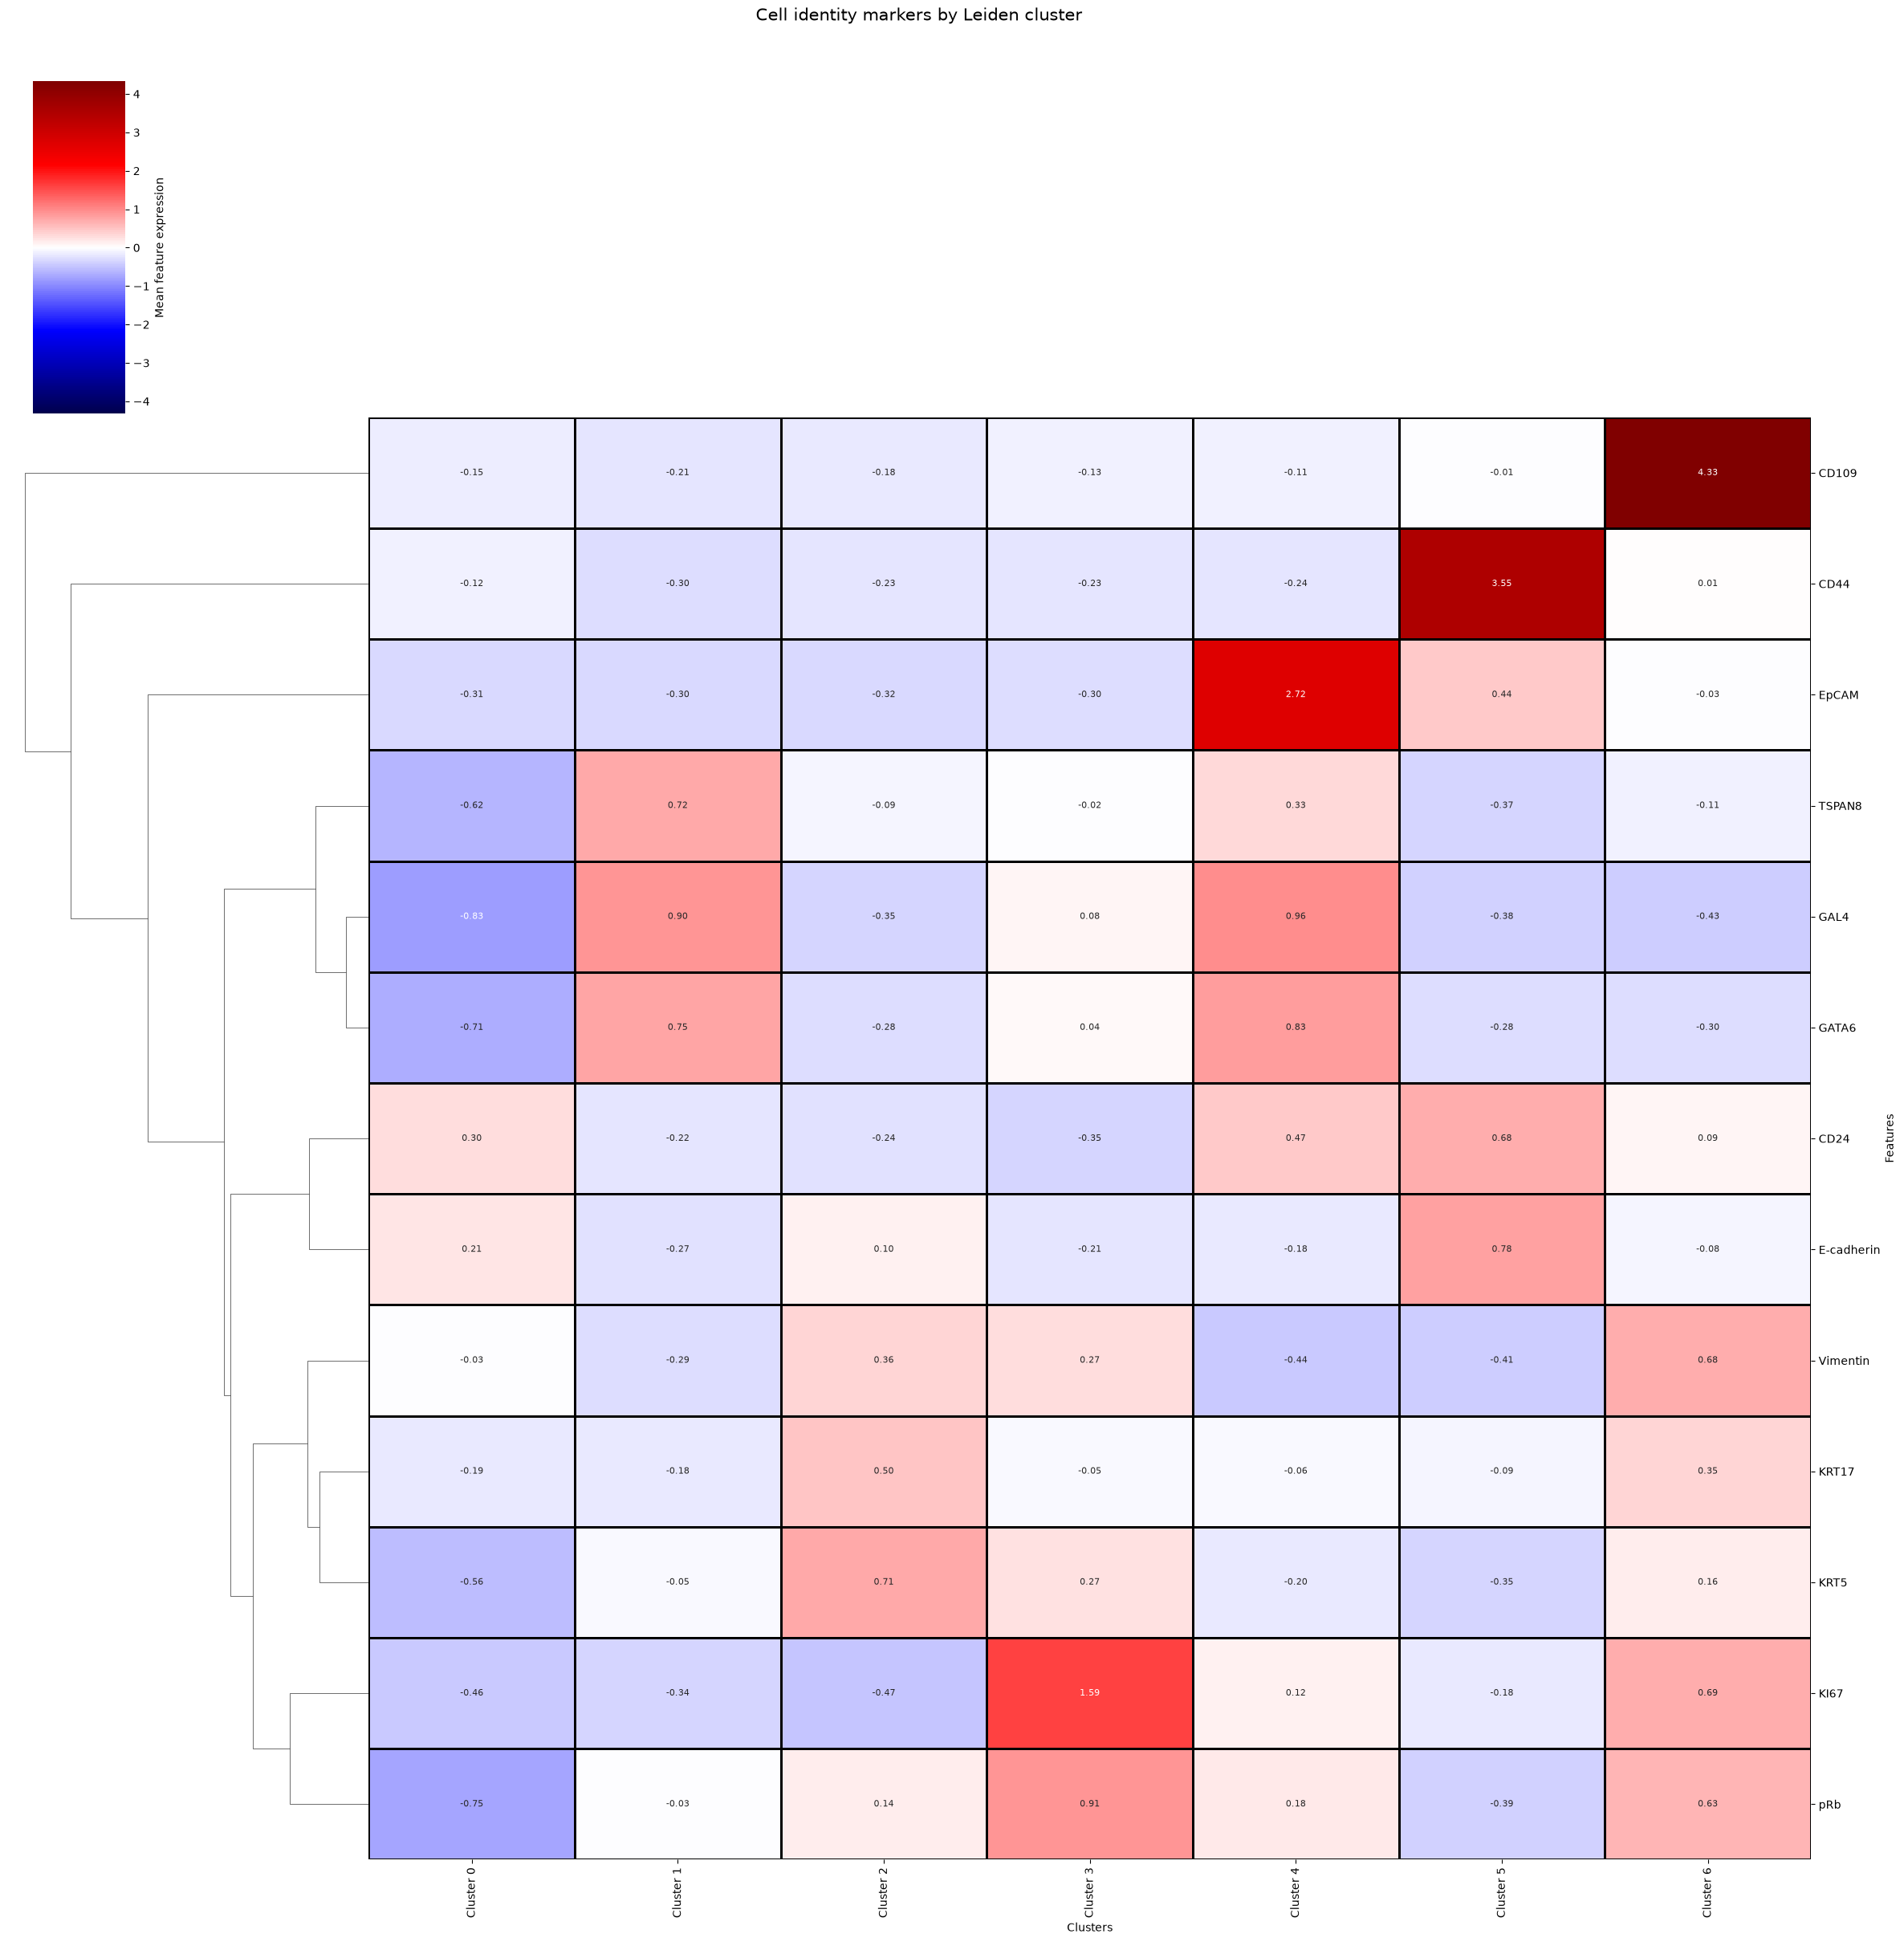

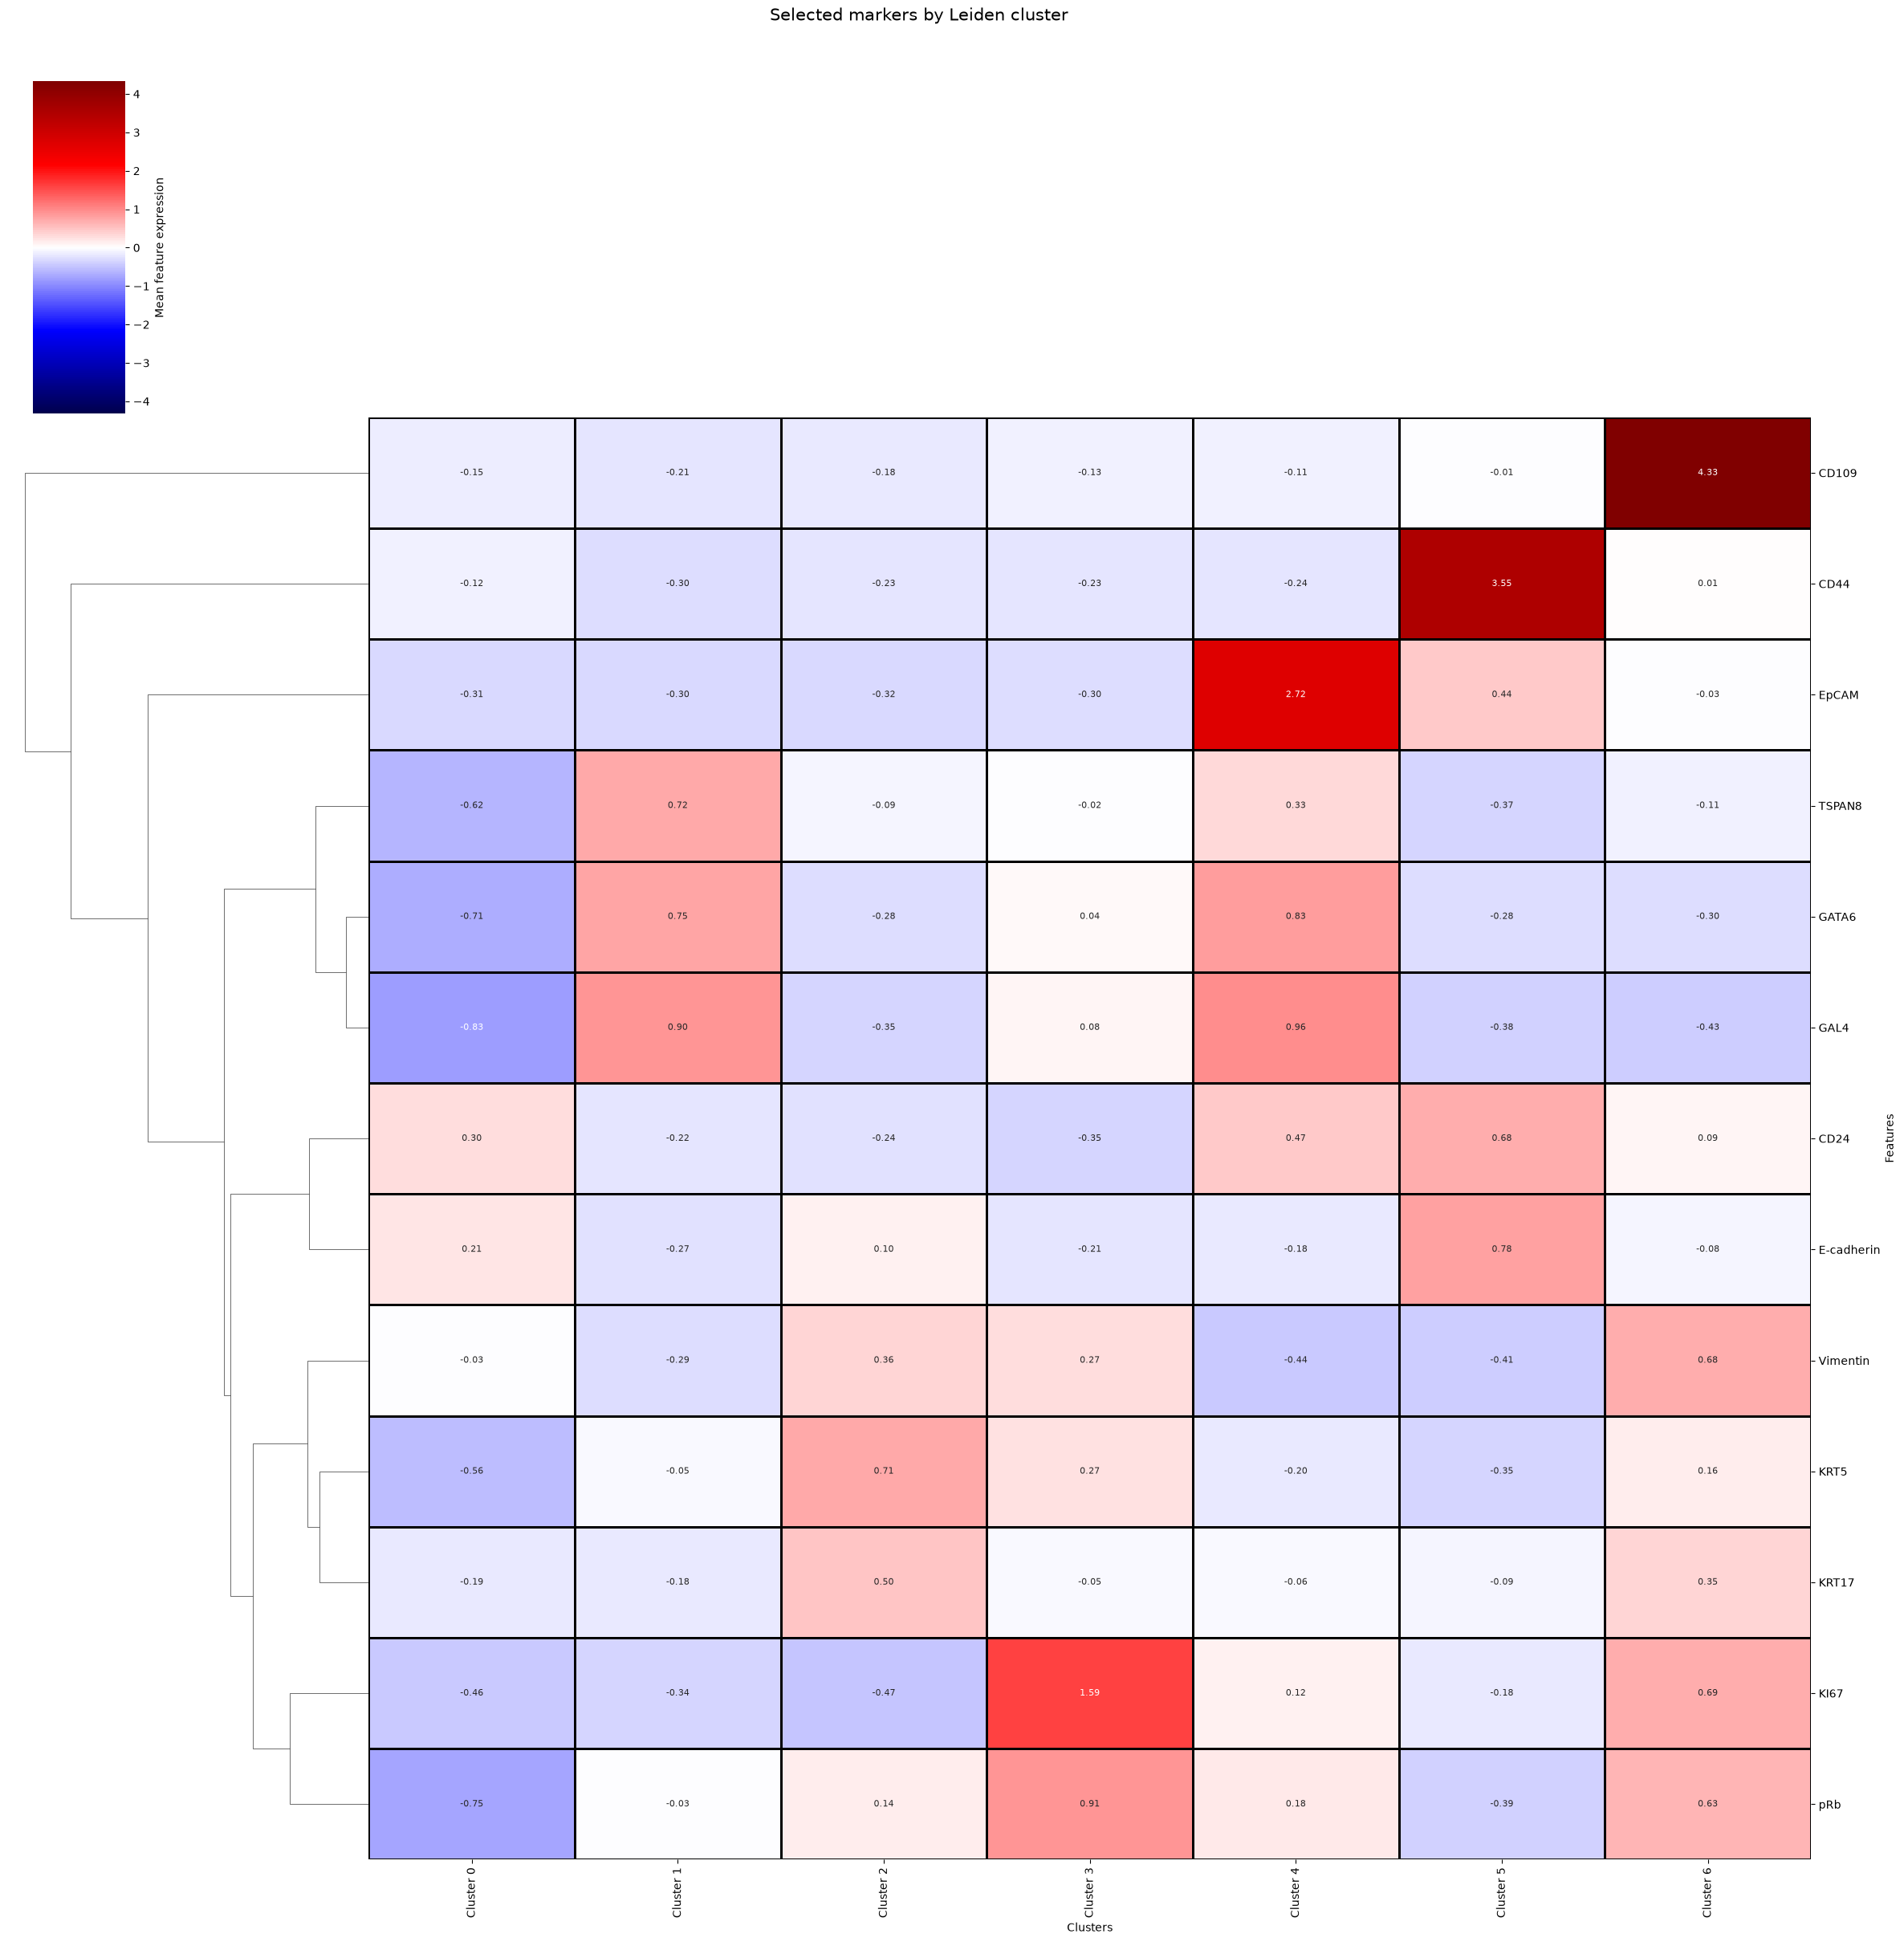

(<seaborn.matrix.ClusterGrid at 0x151fdded0>,
              TSPAN8     GATA6      GAL4      KRT5     KRT17      CD44  \
 Cluster 0 -0.617090 -0.707173 -0.828664 -0.555522 -0.191606 -0.121628   
 Cluster 1  0.716937  0.749499  0.902790 -0.048872 -0.180111 -0.295965   
 Cluster 2 -0.086192 -0.280721 -0.346521  0.710048  0.495970 -0.234918   
 Cluster 3 -0.022028  0.038802  0.075473  0.267323 -0.045503 -0.231124   
 Cluster 4  0.326496  0.829204  0.955317 -0.202508 -0.060139 -0.235327   
 Cluster 5 -0.365903 -0.276612 -0.377067 -0.354176 -0.090484  3.546705   
 Cluster 6 -0.109749 -0.297463 -0.431547  0.162164  0.347194  0.005998   
 
               CD109  Vimentin     EpCAM      CD24  E-cadherin      KI67  \
 Cluster 0 -0.152734 -0.033481 -0.307783  0.303805    0.209039 -0.461439   
 Cluster 1 -0.205277 -0.286702 -0.304236 -0.224515   -0.266244 -0.342526   
 Cluster 2 -0.177243  0.358285 -0.323286 -0.243225    0.101858 -0.474301   
 Cluster 3 -0.127405  0.274646 -0.301412 -0.348818   -0.

In [6]:
df_umap = load_umap(UMAP_ROOT, "all", MARKER_GROUP)
leiden_labels = calc_leiden(df_umap, n_neighbors=100, resolution=0.07, random_state=42)
leiden_dir = OUTPUT_ROOT / "7. Clustering" / "GFP_high_UMAP_Leiden"
leiden_name = "all_cell_identity_Leiden_neighbors100_resolution0.07"
plot_clusters(
    df_umap,
    leiden_labels,
    "Leiden | all | cell_identity",
    leiden_dir / f"{leiden_name}.png",
    point_size=4,
    figsize=(9, 7),
)
plot_clusters_by_condition(
    df_umap,
    leiden_labels,
    ["untreated", "treated"],
    leiden_dir / "Leiden_clusters_by_condition.png",
    figsize=(9, 14),
    point_size=4,
    alpha=0.8,
)
plot_cluster_heatmap(
    df_umap,
    leiden_labels,
    CELL_IDENTITY_MARKERS,
    leiden_dir / "heatmap_cell_identity.png",
    title="Cell identity markers by Leiden cluster",
    figsize=(23, 23),
)
selected_heatmap_markers = [
    "TSPAN8",
    "GATA6",
    "GAL4",
    "KRT5",
    "KRT17",
    "CD44",
    "CD109",
    "Vimentin",
    "EpCAM",
    "CD24",
    "E-cadherin",
    "KI67",
    "pRb",
]
plot_cluster_heatmap(
    df_umap,
    leiden_labels,
    selected_heatmap_markers,
    leiden_dir / "heatmap_selected_features.png",
    title="Selected markers by Leiden cluster",
    figsize=(23, 23),
)

## 3. Manual regions and biological labels

Seed classical and basal regions with the original UMAP inequalities. Fit XGBoost on the aligned scaled GAL4, GATA6, and TSPAN8 values to fill only unassigned rows.

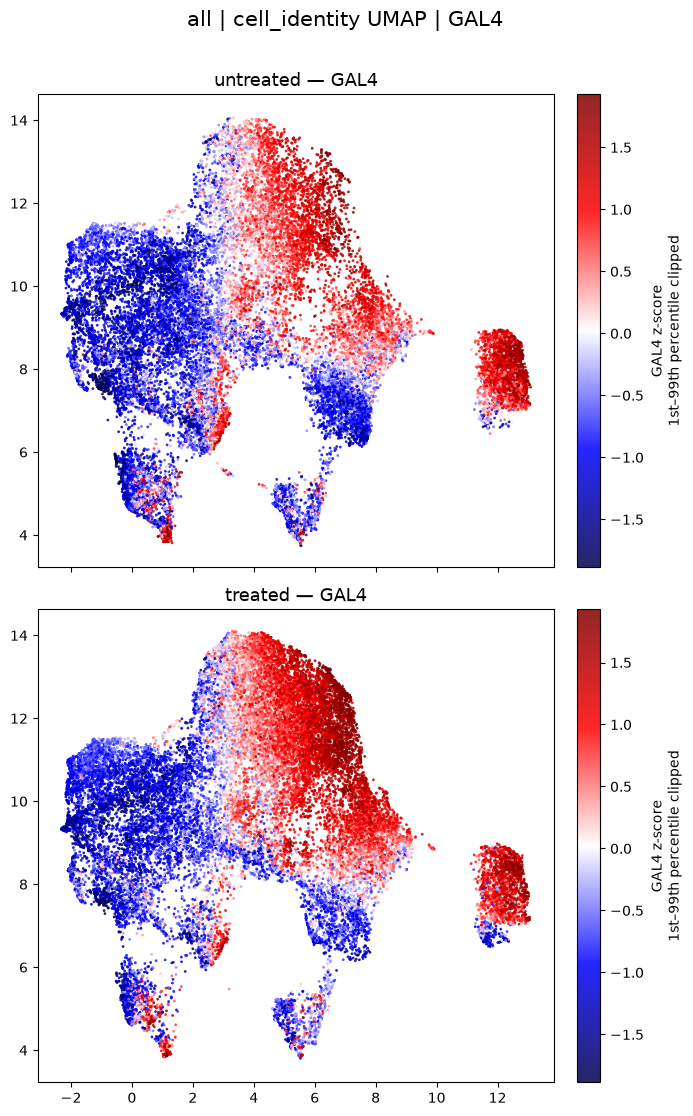

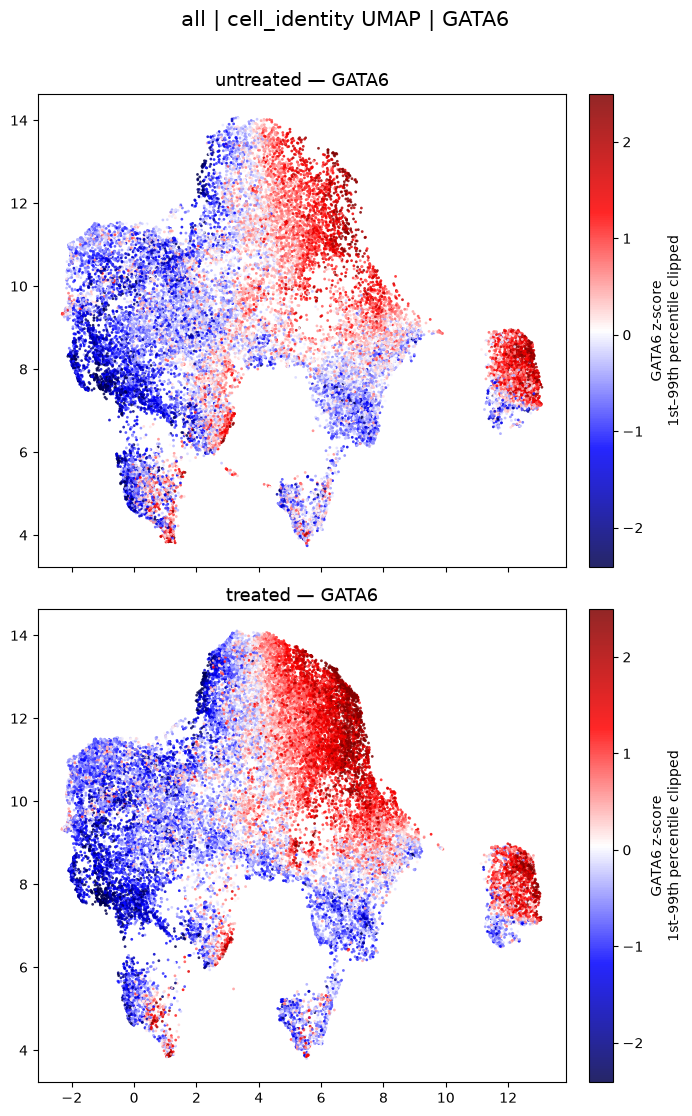

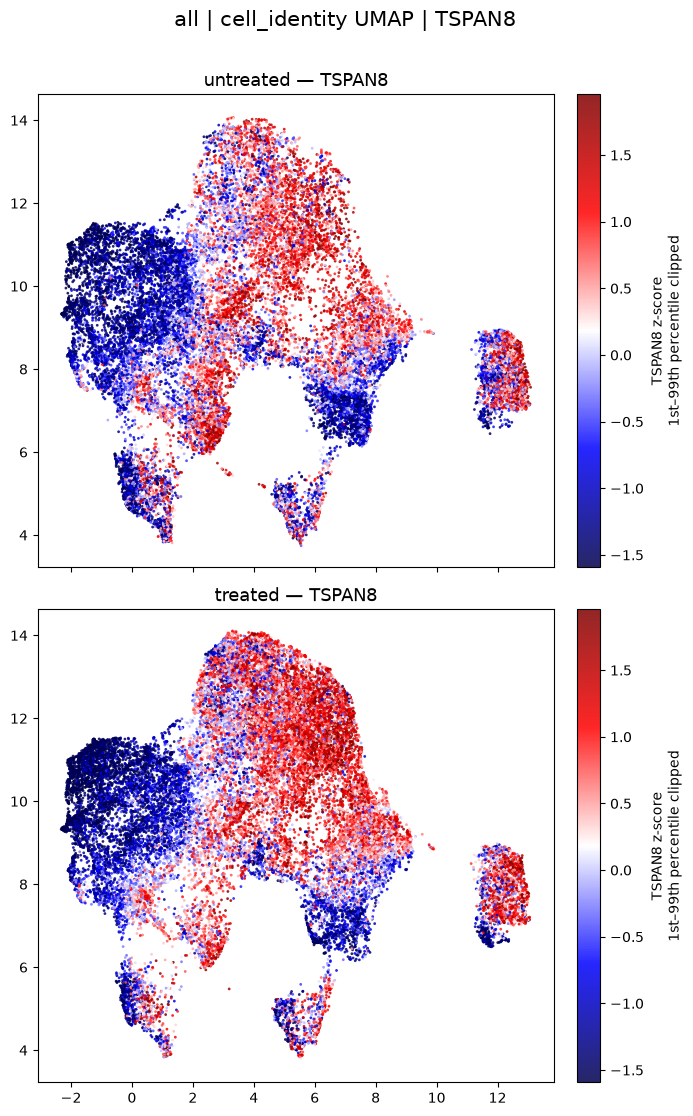

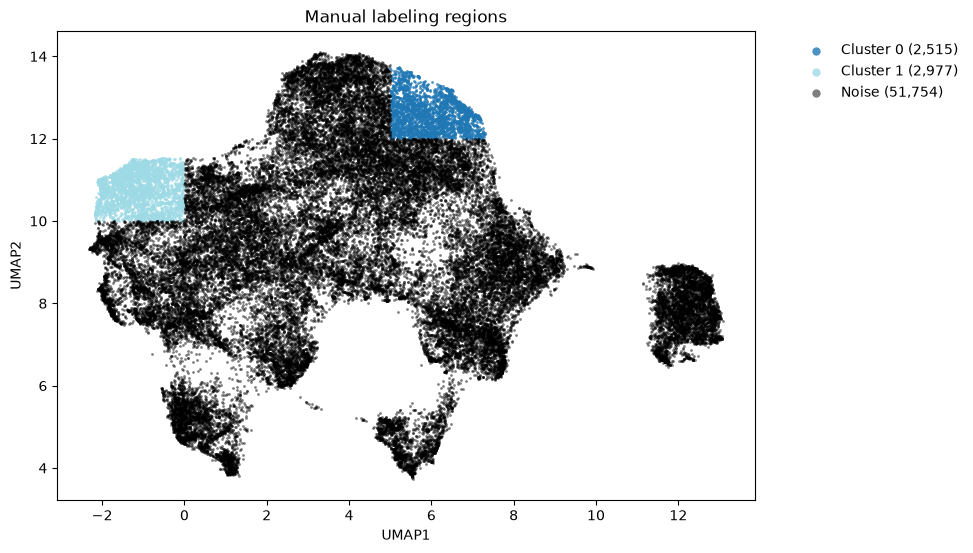

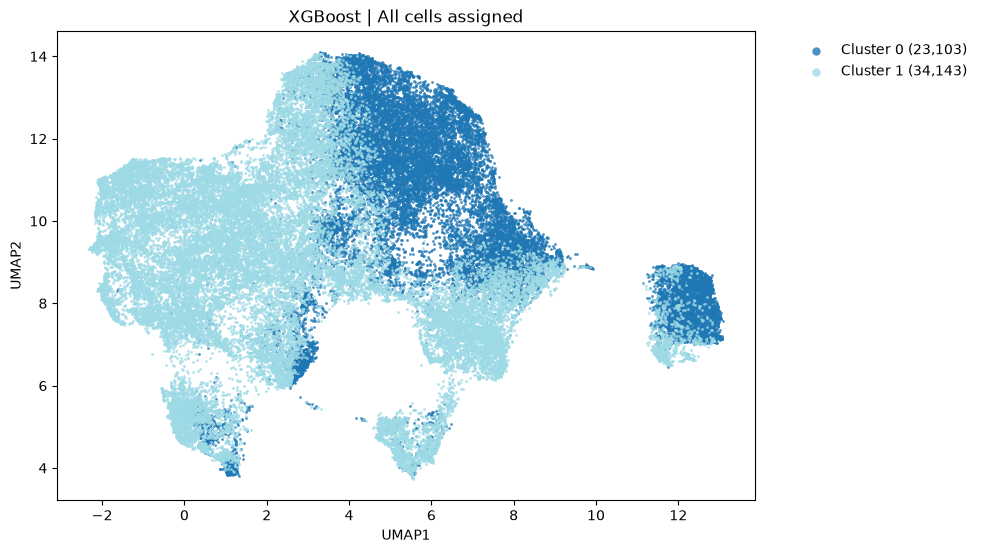

In [7]:
selected_markers = ["GAL4", "GATA6", "TSPAN8"]

manual_labels = assign_manual_labels(df_umap)
label_dir = OUTPUT_ROOT / "7. Clustering" / "Label"
plot_umap_staining(df_umap, ["GAL4", "GATA6", "TSPAN8"], "all", MARKER_GROUP, label_dir)
plot_clusters(df_umap, manual_labels, "Manual labeling regions", label_dir / "manual_clusters.png")
if (
    not pooled_scaled["cell_id"]
    .reset_index(drop=True)
    .equals(df_umap["cell_id"].reset_index(drop=True))
):
    raise ValueError("Pooled scaled expression and UMAP coordinates are not cell-ID/order aligned")
predicted_labels, xgb_model = predict_noise_xgboost(
    pooled_scaled,
    manual_labels,
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    random_state=42,
    n_jobs=1,
    features=selected_markers,
)
plot_clusters(
    df_umap, predicted_labels, "XGBoost | All cells assigned", label_dir / "XGBoost_clusters.png"
)
labeled_data = save_labeled_data(
    pooled_scaled,
    df_umap,
    predicted_labels,
    label_dir / "all_GFP_high_BALANCED_ZSCORED_labeled.csv",
)


## 4. Create Annotations

In [8]:
annotation_map = labeled_data[["cell_uid", "labels"]].copy()
if annotation_map["cell_uid"].isna().any() or not annotation_map["cell_uid"].is_unique:
    raise ValueError("Annotation export requires unique, non-null cell_uid values")
if len(leiden_labels) != len(annotation_map):
    raise ValueError("Leiden clusters are not aligned with annotated cells")
annotation_map["leiden_cluster"] = pd.Series(leiden_labels, index=annotation_map.index).astype(
    "Int64"
)
annotation_map.to_csv(ANNOTATION_FILE, index=False)
print(f"Saved cell annotation map: {ANNOTATION_FILE}")
display(labeled_data["labels"].value_counts(dropna=False))

Saved cell annotation map: /Users/yishai/Desktop/epigenetics_field_theory/results/cell_annotations.csv


labels
basal        34143
classical    23103
Name: count, dtype: int64

## 5. Staining

In [9]:
if staining:
    staining_summary = pd.DataFrame(
        plot_umap_staining(
            coordinates,
            PRESENT_MARKERS,
            "all",
            MARKER_GROUP,
            OUTPUT_ROOT / "6. plots - GFP+ analyses" / "GFP_high_UMAP_marker_staining",
        )
    )
    staining_summary.to_csv(
        OUTPUT_ROOT / "6. plots - GFP+ analyses" / "UMAP_marker_staining_summary.csv", index=False
    )
    display(staining_summary)